## Q1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter

k_format = FuncFormatter(lambda x, pos: f"${x/1000:.0f}K")

# --- settings -------------------------------------------------------------
DATA_PATH = "../figures/apartment_data.csv"   # same path as the original notebook
COST_LOW, COST_HIGH = 40_000, 85_000          # range used in the original EDA plots
# --------------------------------------------------------------------------

raw = pd.read_csv(DATA_PATH)
d = raw.drop_duplicates().copy()               # keep the result this time
print(f"raw rows: {len(raw):,} -> after removing exact duplicates: {len(d):,}")
print(f"Job # still repeated after dedup: {d['Job #'].duplicated().sum():,}")

d["Initial Cost"] = pd.to_numeric(
    d["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
d["Date"] = pd.to_datetime(d["Fully Permitted"], errors="coerce")
d["Year"] = d["Date"].dt.year
d["Zoning Type"] = d["Zoning Dist1"].astype(str).str[0].where(d["Zoning Dist1"].notna(), "UNKNOWN")
d["Borough"] = d["Borough"].str.upper().str.strip()
d["Job Type"] = d["Job Type"].str.upper().str.strip()
d = d.dropna(subset=["Initial Cost"])

share_in_range = d["Initial Cost"].between(COST_LOW, COST_HIGH).mean()
print(f"permits inside ${COST_LOW:,}-${COST_HIGH:,}: {share_in_range:.0%} "
      f"({(~d['Initial Cost'].between(COST_LOW, COST_HIGH)).sum():,} outside)")

eda_df = d[d["Initial Cost"].between(COST_LOW, COST_HIGH)].copy()
print(f"eda_df rows: {len(eda_df):,}")
print(d["Borough"].value_counts())

raw rows: 19,613 -> after removing exact duplicates: 13,509
Job # still repeated after dedup: 106
permits inside $40,000-$85,000: 100% (39 outside)
eda_df rows: 13,470
Borough
MANHATTAN        10697
BROOKLYN          1870
QUEENS             561
BRONX              357
STATEN ISLAND       24
Name: count, dtype: int64


distinct declared values: 46
share that are multiples of $10,000: 49%
share that are multiples of  $5,000: 72%

most frequent declared values:
Initial Cost
40000.0    1969
50000.0    1867
60000.0    1267
45000.0     839
80000.0     792
75000.0     745
70000.0     714
65000.0     568
55000.0     549
85000.0     363
Name: count, dtype: int64


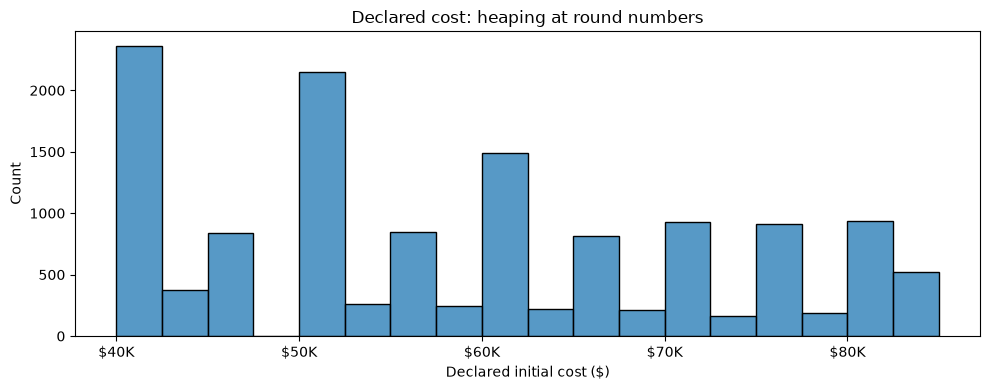

In [2]:
c = d["Initial Cost"]
print("distinct declared values:", c.nunique())
print(f"share that are multiples of $10,000: {(c % 10_000 == 0).mean():.0%}")
print(f"share that are multiples of  $5,000: {(c % 5_000 == 0).mean():.0%}")
print("\nmost frequent declared values:")
print(c.value_counts().head(10))

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(c[c <= 150_000], binwidth=2_500, ax=ax)
ax.set_title("Declared cost: heaping at round numbers")
ax.set_xlabel("Declared initial cost ($)")
ax.xaxis.set_major_formatter(k_format)
plt.tight_layout()
plt.show()

cpi_annual.csv not found: showing nominal medians only


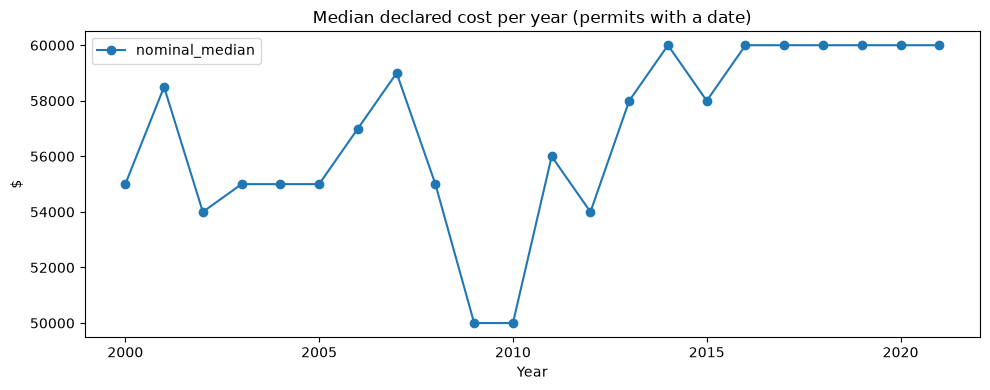

,n,nominal_median
Year,,
2000.0,153,55000.0
2001.0,276,58500.0
2002.0,405,54000.0
2003.0,491,55000.0
2004.0,518,55000.0
2005.0,587,55000.0
2006.0,577,57000.0
2007.0,610,59000.0
2008.0,635,55000.0


In [3]:
by_year = d.groupby("Year")["Initial Cost"].agg(n="count", nominal_median="median")
by_year = by_year[by_year["n"] >= 30]

cpi_file = Path("cpi_annual.csv")
if cpi_file.exists():
    cpi = pd.read_csv(cpi_file)
    base = cpi.loc[cpi["Year"] == cpi["Year"].max(), "CPI"].iloc[0]
    tmp = d.merge(cpi, on="Year", how="left")
    tmp["Real Cost"] = tmp["Initial Cost"] * base / tmp["CPI"]
    real = tmp.groupby("Year")["Real Cost"].median()
    by_year["real_median"] = real
    print(f"real values are in {int(cpi['Year'].max())} dollars")
else:
    print("cpi_annual.csv not found: showing nominal medians only")

by_year.drop(columns="n").plot(figsize=(10, 4), marker="o",
                               title="Median declared cost per year (permits with a date)")
plt.ylabel("$")
plt.tight_layout()
plt.show()
by_year

## Q2. Borough differences: type of work or price?

The dataset only contains alterations (A1, A2, A3), so job type measures the scope of the work,
not new buildings vs. alterations. We first check the job-type mix per borough, then compare medians
within each borough and job type.

Job-type mix per borough (% of permits):
Job Type         A1    A2   A3
Borough                       
BRONX          19.3  80.1  0.6
BROOKLYN       17.4  82.0  0.5
MANHATTAN       3.7  96.1  0.2
QUEENS         24.8  74.0  1.2
STATEN ISLAND  58.3  41.7  0.0

Permit counts:
Job Type        A1     A2  A3
Borough                      
BRONX           69    286   2
BROOKLYN       326   1534  10
MANHATTAN      392  10283  22
QUEENS         139    415   7
STATEN ISLAND   14     10   0

Median declared cost (cells with n < 30 hidden):
Job Type        A1       A2
Borough                    
BRONX      50000.0  54500.0
BROOKLYN   60000.0  60000.0
MANHATTAN  55000.0  57000.0
QUEENS     50000.0  55000.0


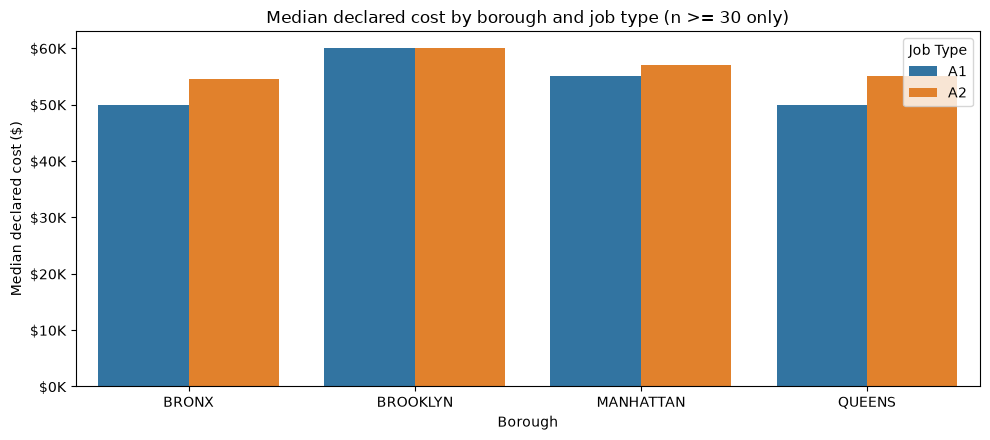

In [4]:
mix = pd.crosstab(d["Borough"], d["Job Type"], normalize="index").round(3) * 100
counts = pd.crosstab(d["Borough"], d["Job Type"])
print("Job-type mix per borough (% of permits):")
print(mix)
print("\nPermit counts:")
print(counts)

tab = (d.groupby(["Borough", "Job Type"])["Initial Cost"]
         .agg(n="count", median="median").reset_index())
print("\nMedian declared cost (cells with n < 30 hidden):")
print(tab[tab["n"] >= 30].pivot(index="Borough", columns="Job Type", values="median"))

g = tab[tab["n"] >= 30]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=g, x="Borough", y="median", hue="Job Type", ax=ax)
ax.set_title("Median declared cost by borough and job type (n >= 30 only)")
ax.set_ylabel("Median declared cost ($)")
ax.yaxis.set_major_formatter(k_format)
plt.tight_layout()
plt.show()

In [5]:
# Does adding job type change the borough differences? (log cost, Manhattan = reference)
from sklearn.linear_model import LinearRegression

m = d.copy()
y = np.log(m["Initial Cost"])
ref = "MANHATTAN"

X_b = pd.get_dummies(m["Borough"]).drop(columns=ref).astype(float)
X_bj = pd.concat([X_b, pd.get_dummies(m["Job Type"], prefix="JT", drop_first=True).astype(float)], axis=1)

coef_b = pd.Series(LinearRegression().fit(X_b, y).coef_, index=X_b.columns)
coef_bj = pd.Series(LinearRegression().fit(X_bj, y).coef_, index=X_bj.columns)

out = pd.DataFrame({"borough only": coef_b, "borough + job type": coef_bj[X_b.columns]}).round(3)
out["approx % vs Manhattan (borough only)"] = ((np.exp(out["borough only"]) - 1) * 100).round(1)
out["approx % vs Manhattan (with job type)"] = ((np.exp(out["borough + job type"]) - 1) * 100).round(1)
print("Borough effect on declared cost relative to", ref)
out

Borough effect on declared cost relative to MANHATTAN


,borough only,borough + job type,approx % vs Manhattan (borough only),approx % vs Manhattan (with job type)
BRONX,-0.019,-0.019,-1.9,-1.9
BROOKLYN,0.020,0.020,2.0,2.0
QUEENS,-0.027,-0.026,-2.7,-2.6
STATEN ISLAND,0.058,0.056,6.0,5.8


## Q3. Which columns would leak the answer if we predicted cost?

Candidates: `Job #` (sequential, encodes filing time and borough), `Bin #`, `Block`, `Lot` (identify the building;
many buildings have several permits), and `Fully Permitted` (known only after approval).
We test this by comparing the same model with a random split and with a split grouped by building.

In [ ]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

mm = d.reset_index(drop=True)
y = np.log(mm["Initial Cost"])

def score(cols, grouped, seed=0):
    X = pd.get_dummies(mm[cols], columns=mm[cols].select_dtypes(exclude="number").columns)
    if grouped:
        tr, te = next(GroupShuffleSplit(test_size=0.25, random_state=seed)
                      .split(X, y, groups=mm["Bin #"]))
    else:
        tr, te = train_test_split(np.arange(len(mm)), test_size=0.25, random_state=seed)
    rf = RandomForestRegressor(n_estimators=150, min_samples_leaf=3,
                               n_jobs=-1, random_state=seed).fit(X.iloc[tr], y.iloc[tr])
    return round(r2_score(y.iloc[te], rf.predict(X.iloc[te])), 3)

leaky = ["Bin #", "Block", "Lot", "Job #"]
safe = ["Borough", "Job Type", "Zoning Type"]

results = pd.Series({
    "leaky + safe cols, random split":  score(leaky + safe, grouped=False),
    "leaky + safe cols, split by building": score(leaky + safe, grouped=True),
    "safe cols only, split by building": score(safe, grouped=True),
}, name="R2 on log cost")
print("Compare the rows: a big drop from row 1 to row 2 means the building columns leak.")
results

Compare the rows: a big drop from row 1 to row 2 means the building columns leak.


leaky + safe cols, random split         0.056
leaky + safe cols, split by building   -0.023
safe cols only, split by building       0.003
Name: R2 on log cost, dtype: float64

: 

## Limitations

- Initial cost is declared by the applicant, rounded, and not adjusted for inflation unless stated.
- Most permits are in Manhattan and are type A2, so A1/A3 and the smaller boroughs have little data.
- The EDA plots use declared costs between $40K and $85K only; results do not describe permits outside that range.
- [Add anything else you found.]